Usage example of MediaPipe Pose Solution API in Python (see also http://solutions.mediapipe.dev/pose).

In [1]:
import requests
import os
from PIL import Image
from io import BytesIO
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import mediapipe as mp

2025-04-07 10:42:25.171636: I external/local_xla/xla/tsl/cuda/cudart_stub.cc:32] Could not find cuda drivers on your machine, GPU will not be used.
2025-04-07 10:42:26.431292: I external/local_xla/xla/tsl/cuda/cudart_stub.cc:32] Could not find cuda drivers on your machine, GPU will not be used.
2025-04-07 10:42:26.633950: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1744036946.936981  936786 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1744036947.028990  936786 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1744036947.918883  936786 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linkin

Upload any image that that has a person. We take two example images from the web: https://unsplash.com/photos/v4zceVZ5HK8 and https://unsplash.com/photos/e_rhazQLaSs.


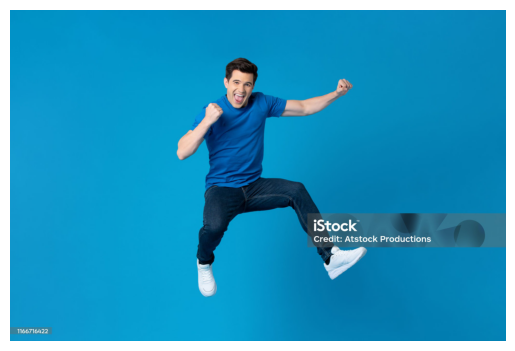

In [2]:


# file1 = 'https://unsplash.com/photos/woman-wearing-karate-gi-v4zceVZ5HK8'
file = 'https://media.istockphoto.com/id/1166716422/photo/american-man-jumping-and-enyoying-his-success.jpg?s=2048x2048&w=is&k=20&c=0M29rxRlL_vQEcACs1-SvSdDN9VZzxQjjXScD0w9W5Q='

response = requests.get(file)
save_path = f'test.jpg'
with open(save_path, 'wb') as f:
    f.write(response.content)
image = Image.open(save_path)

plt.figure()
plt.imshow(image)
plt.axis('off')
plt.show()

All MediaPipe Solutions Python API examples are under mp.solutions.

For the MediaPipe Pose solution, we can access this module as `mp_pose = mp.solutions.pose`.

You may change the parameters, such as `static_image_mode` and `min_detection_confidence`, during the initialization. Run `help(mp_pose.Pose)` to get more informations about the parameters.

In [3]:

mp_holistic = mp.solutions.holistic
mp_drawing = mp.solutions.drawing_utils
mp_drawing_styles = mp.solutions.drawing_styles

mp_holistic.POSE_CONNECTIONS

frozenset({(0, 1),
           (0, 4),
           (1, 2),
           (2, 3),
           (3, 7),
           (4, 5),
           (5, 6),
           (6, 8),
           (9, 10),
           (11, 12),
           (11, 13),
           (11, 23),
           (12, 14),
           (12, 24),
           (13, 15),
           (14, 16),
           (15, 17),
           (15, 19),
           (15, 21),
           (16, 18),
           (16, 20),
           (16, 22),
           (17, 19),
           (18, 20),
           (23, 24),
           (23, 25),
           (24, 26),
           (25, 27),
           (26, 28),
           (27, 29),
           (27, 31),
           (28, 30),
           (28, 32),
           (29, 31),
           (30, 32)})

In [4]:
import cv2

def mediapipe_detection(image, model):
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    image.flags.writeable = False
    results  = model.process(image)
    image.flags.writeable = True
    image = cv2.cvtColor(image, cv2.COLOR_RGB2BGR)
    return image, results

I0000 00:00:1744036974.864238  936786 gl_context_egl.cc:85] Successfully initialized EGL. Major : 1 Minor: 5
I0000 00:00:1744036975.046548  937116 gl_context.cc:369] GL version: 3.2 (OpenGL ES 3.2 NVIDIA 550.54.14), renderer: NVIDIA A100-SXM4-80GB/PCIe/SSE2
INFO: Created TensorFlow Lite XNNPACK delegate for CPU.
W0000 00:00:1744036975.145917  937034 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1744036975.166713  937067 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1744036975.181933  937076 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1744036975.186952  937077 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference

Pose landmarks of test:


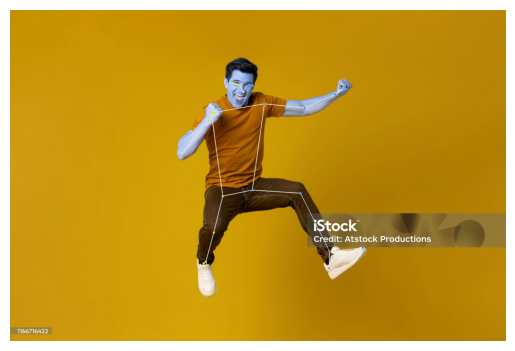

In [5]:
name = 'test'

# Run MediaPipe Pose and draw pose landmarks.
with mp_holistic.Holistic(min_detection_confidence=0.5, min_tracking_confidence=0.5) as holistic:
  # Convert the BGR image to RGB and process it with MediaPipe Pose.
  image, results = mediapipe_detection(cv2.imread(save_path), holistic)

  # Print nose landmark.
  image_hight, image_width, _ = image.shape
  if not results.pose_landmarks:
    print('no landmarks')
  # print(
  #   f'Nose coordinates: ('
  #   f'{results.pose_landmarks.landmark[mp_pose.PoseLandmark.NOSE].x * image_width}, '
  #   f'{results.pose_landmarks.landmark[mp_pose.PoseLandmark.NOSE].y * image_hight})'
  # )

  # Draw pose landmarks.
  print(f'Pose landmarks of {name}:')
  annotated_image = image.copy()
  mp_drawing.draw_landmarks(
      annotated_image,
      results.pose_landmarks,
      mp_holistic.POSE_CONNECTIONS,
      landmark_drawing_spec=mp_drawing_styles.get_default_pose_landmarks_style())
  plt.figure()
  plt.imshow(annotated_image)
  plt.axis('off')
  plt.show()

I0000 00:00:1744036975.432652  936786 gl_context_egl.cc:85] Successfully initialized EGL. Major : 1 Minor: 5
I0000 00:00:1744036975.491436  937260 gl_context.cc:369] GL version: 3.2 (OpenGL ES 3.2 NVIDIA 550.54.14), renderer: NVIDIA A100-SXM4-80GB/PCIe/SSE2
W0000 00:00:1744036975.549333  937133 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1744036975.570276  937211 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1744036975.573483  937230 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1744036975.573722  937231 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:17

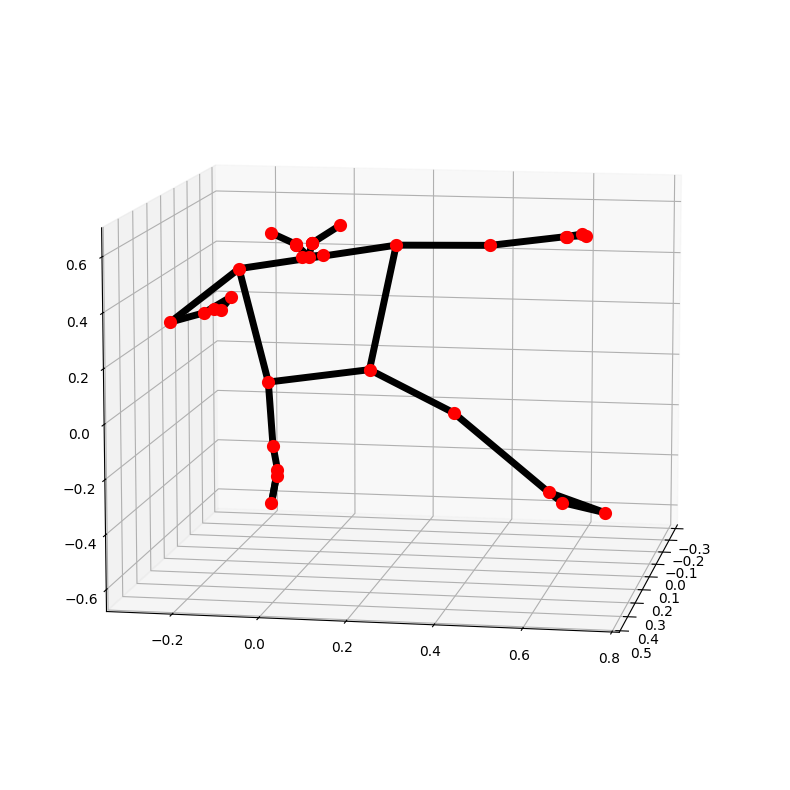

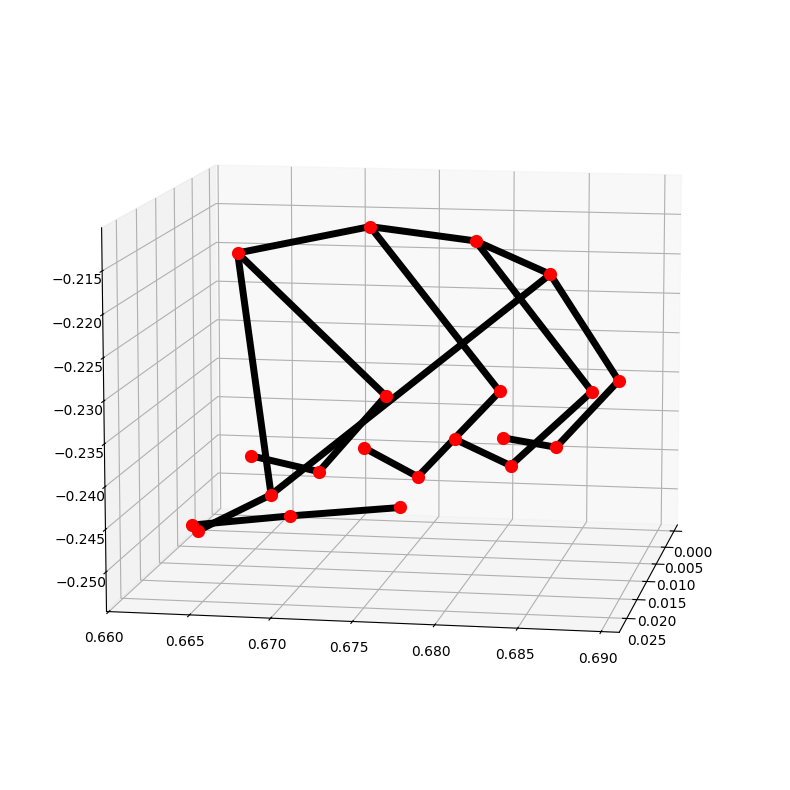

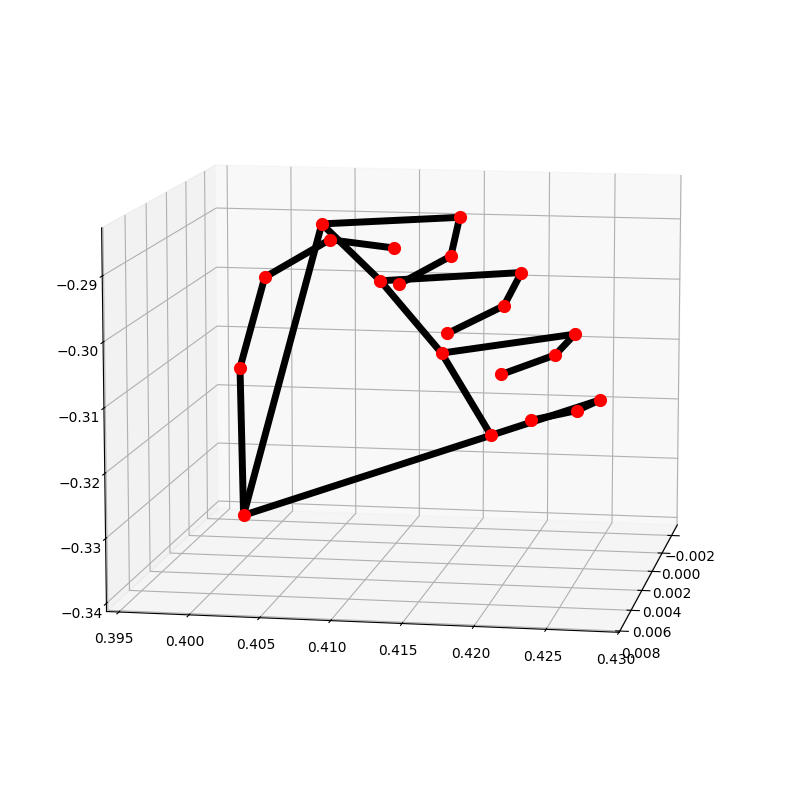

In [6]:
def print_graph(mp_holistic, save_path):
    # Run MediaPipe Pose and plot 3d pose world landmarks.
    with mp_holistic.Holistic(min_detection_confidence=0.5, min_tracking_confidence=0.5) as holistic:
        image, results = mediapipe_detection(cv2.imread(save_path), holistic)

        # Print the real-world 3D coordinates of nose in meters with the origin at
        # the center between hips.
        # print('Nose world landmark:'),
        # print(results.pose_world_landmarks.landmark[mp_holistic.PoseLandmark.NOSE])

        # Plot pose world landmarks.
        mp_drawing.plot_landmarks(results.pose_world_landmarks, mp_holistic.POSE_CONNECTIONS)
        mp_drawing.plot_landmarks(results.left_hand_landmarks, mp_holistic.HAND_CONNECTIONS)
        mp_drawing.plot_landmarks(results.right_hand_landmarks, mp_holistic.HAND_CONNECTIONS)

print_graph(mp_holistic, save_path)

I0000 00:00:1744036979.654427  936786 gl_context_egl.cc:85] Successfully initialized EGL. Major : 1 Minor: 5
I0000 00:00:1744036979.711343  937404 gl_context.cc:369] GL version: 3.2 (OpenGL ES 3.2 NVIDIA 550.54.14), renderer: NVIDIA A100-SXM4-80GB/PCIe/SSE2
W0000 00:00:1744036979.761293  937281 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1744036979.781212  937351 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1744036979.797797  937389 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1744036979.802720  937388 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:17

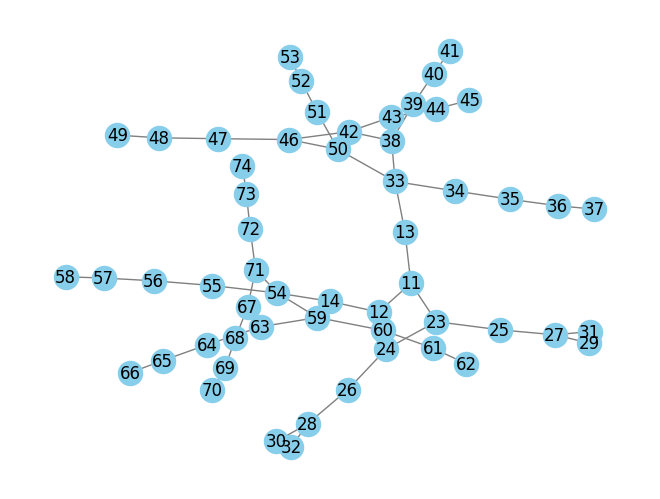

In [7]:
import networkx as nx

def create_pose_graph(mp_holistic, save_path, with_hands=True):
    with mp_holistic.Holistic(min_detection_confidence=0.5, min_tracking_confidence=0.5) as holistic:
        image, results = mediapipe_detection(cv2.imread(save_path), holistic)
        
        ignore_face = [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10]
        ignore_hands = [18, 20, 22, 17, 19, 21]
                        # 25, 27, 29, 31, 14, 16, 23]
        left_wrist = 15
        right_wrist = 16

        max_i = 0
        pose_G = nx.Graph()
        # first add nodes from landmarks
        for i, landmark in enumerate(results.pose_landmarks.landmark):
            if i not in ignore_face and i not in ignore_hands:
                if i == 15 or i == 16:
                    # print(landmark.x, landmark.y, landmark.z)
                    continue
                pose_G.add_node(i, pos=(landmark.x, landmark.y, landmark.z))
        max_i = i+1

        for connection in mp_holistic.POSE_CONNECTIONS:
            if connection[0] in pose_G.nodes() and connection[1] in pose_G.nodes():
                pose_G.add_edge(connection[0], connection[1])
        # nx.draw(pose_G, with_labels=True, node_color='skyblue', edge_color='gray')

        if with_hands:
            for i, landmark in enumerate(results.left_hand_landmarks.landmark):
                if i == 0:
                    pose_G.add_edge(13, max_i)
                    # print(landmark.x, landmark.y, landmark.z)
                # if i != 0:
                pose_G.add_node(max_i+i, pos=(landmark.x, landmark.y, landmark.z))

            # hand has 21 nodes so the nodes are now 33+0, 33+1, 33+2, ... 33+20
            # because the pose has 32 nodes 
            for connection in mp_holistic.HAND_CONNECTIONS:
                # if connection[0] == 0:
                #     pose_G.add_edge(15, connection[1]+max_i)
                # elif connection[1] == 0:
                #     pose_G.add_edge(connection[0]+max_i, 15)
                # else:
                pose_G.add_edge(connection[0]+max_i, connection[1]+max_i)
            max_i += i+1

            for i, landmark in enumerate(results.right_hand_landmarks.landmark):
                if i == 0:
                    pose_G.add_edge(14, max_i)
                    # print(landmark.x, landmark.y, landmark.z)
                pose_G.add_node(max_i+i, pos=(landmark.x, landmark.y, landmark.z))

            # hand has 53 nodes so the nodes are now 53+0, 53+1, 53+2, ... 53+20
            # because the pose has 32 nodes and left hand had 21
            for connection in mp_holistic.HAND_CONNECTIONS:
                # if connection[0] == 0:
                #     pose_G.add_edge(16, connection[1]+max_i)
                # elif connection[1] == 0:
                #     pose_G.add_edge(connection[1]+max_i, 16)
                # else:
                pose_G.add_edge(connection[0]+max_i, connection[1]+max_i)
            # max_i = i

    return pose_G

pose_graph = create_pose_graph(mp_holistic, save_path, with_hands=True)
nx.draw(pose_graph, with_labels=True, node_color='skyblue', edge_color='gray')
pose_graph

I0000 00:00:1744036980.013664  936786 gl_context_egl.cc:85] Successfully initialized EGL. Major : 1 Minor: 5
I0000 00:00:1744036980.071438  937534 gl_context.cc:369] GL version: 3.2 (OpenGL ES 3.2 NVIDIA 550.54.14), renderer: NVIDIA A100-SXM4-80GB/PCIe/SSE2
W0000 00:00:1744036980.120734  937407 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1744036980.140186  937485 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1744036980.143774  937515 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1744036980.143774  937509 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:17

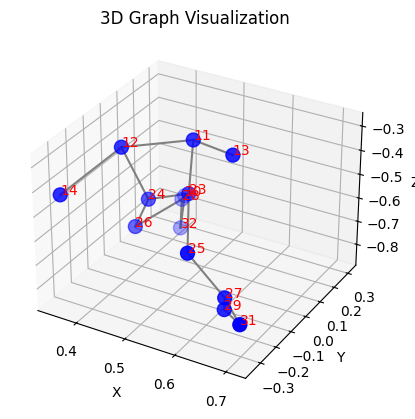

I0000 00:00:1744036980.361819  936786 gl_context_egl.cc:85] Successfully initialized EGL. Major : 1 Minor: 5
I0000 00:00:1744036980.421212  937663 gl_context.cc:369] GL version: 3.2 (OpenGL ES 3.2 NVIDIA 550.54.14), renderer: NVIDIA A100-SXM4-80GB/PCIe/SSE2
W0000 00:00:1744036980.471044  937537 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1744036980.492138  937614 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1744036980.494259  937562 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1744036980.495709  937560 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:17

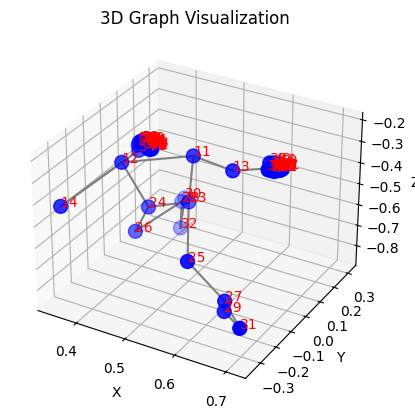

In [8]:
# Extract node positions
import numpy as np

def visualize_pose(pose_graph, show_nodes=False):
    x_vals, z_vals, y_vals = zip(*[data['pos'] for node, data in pose_graph.nodes(data=True)])

    # Plot the graph
    fig = plt.figure()
    ax = fig.add_subplot(111, projection='3d')

    # Draw nodes
    new = ()
    for z in z_vals:
        new += (z*-1,)
    z_vals = new
    ax.scatter(x_vals, y_vals, z_vals, c='blue', s=100)

    # Draw edges
    nodes = pose_graph.nodes(data=True)
    for edge in pose_graph.edges():
        x_coords = [nodes[edge[0]]['pos'][0], nodes[edge[1]]['pos'][0]]
        z_coords = [nodes[edge[0]]['pos'][1]*-1, nodes[edge[1]]['pos'][1]*-1]
        y_coords = [nodes[edge[0]]['pos'][2], nodes[edge[1]]['pos'][2]]
        ax.plot(x_coords, y_coords, z_coords, color='gray')

    # Annotate nodes
    if show_nodes:
        for node in nodes:
            x, z, y = node[1]['pos']
            x, y, z = x, y, z*-1
            ax.text(x, y, z, f'{node[0]}', color='red')

    # Labels and show
    ax.set_xlabel('X')
    ax.set_ylabel('Y')
    ax.set_zlabel('Z')
    plt.title('3D Graph Visualization')
    plt.show()

pose_graph = create_pose_graph(mp_holistic, save_path, with_hands=False)
visualize_pose(pose_graph, True)


pose_graph = create_pose_graph(mp_holistic, save_path, with_hands=True)
visualize_pose(pose_graph, True)

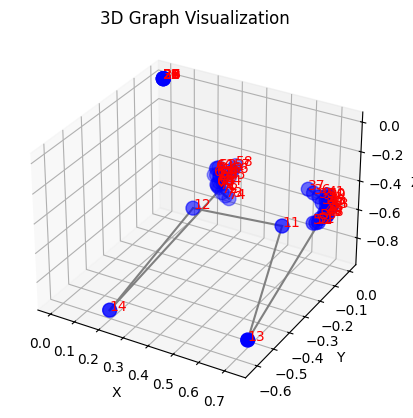

(56, 56)
56


(-0.5, 341.5, 255.5, -0.5)

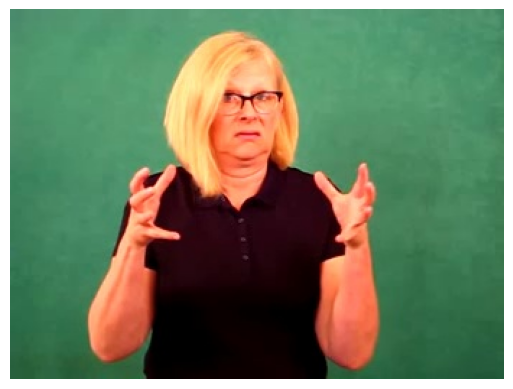

In [9]:
import pickle
import networkx
G = pickle.load(open('/home/tkg5kq/.cache/kagglehub/datasets/risangbaskoro/wlasl-processed/versions/5/graphs/a_lot/02126/0050', 'rb'))
# pose_graph = create_pose_graph(mp_holistic, save_path, with_hands=True)
visualize_pose(G, True)
print(networkx.to_numpy_array(G).astype(np.float32).shape)
print(len(G.nodes()))
plt.figure()
image_rgb = cv2.cvtColor(cv2.imread('/home/tkg5kq/.cache/kagglehub/datasets/risangbaskoro/wlasl-processed/versions/5/frames_wlasl_10/a_lot/02126/image_0050.jpg'), cv2.COLOR_BGR2RGB)
plt.imshow(image_rgb)
plt.axis('off')

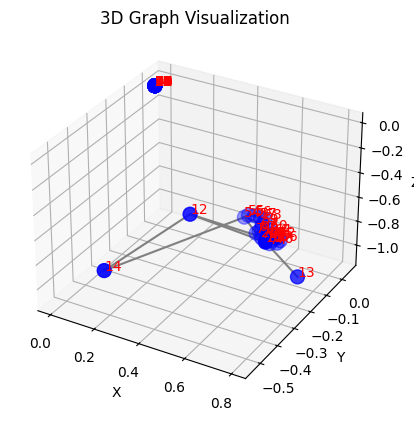

(56, 56)
56


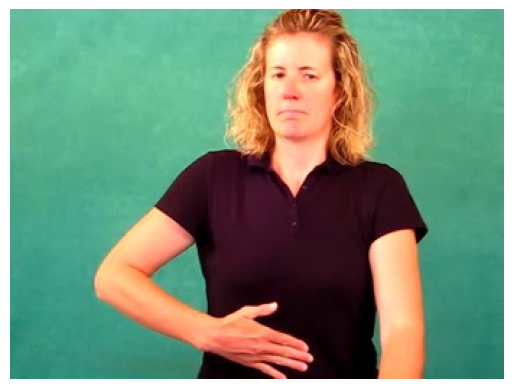

In [10]:
import pickle
import networkx
G = pickle.load(open('/home/tkg5kq/.cache/kagglehub/datasets/risangbaskoro/wlasl-processed/versions/5/graphs/abdomen/00336/0042', 'rb'))
# pose_graph = create_pose_graph(mp_holistic, save_path, with_hands=True)
visualize_pose(G, True)
print(networkx.to_numpy_array(G).astype(np.float32).shape)
print(len(G.nodes()))
plt.figure()
image_rgb = cv2.cvtColor(cv2.imread('/home/tkg5kq/.cache/kagglehub/datasets/risangbaskoro/wlasl-processed/versions/5/frames_wlasl_10/abdomen/00336/image_0042.jpg'), cv2.COLOR_BGR2RGB)
plt.imshow(image_rgb)
plt.axis('off')
plt.show()


In [1]:
import os
os.environ["TF_USE_LEGACY_KERAS"] = "1"

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch_geometric.nn import GCNConv, global_mean_pool
import sys
sys.path.insert(0, '../.')
import wlasl_dataloader


2025-04-07 15:13:28.429396: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1744053208.500602   28429 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1744053208.513306   28429 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1744053208.596906   28429 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1744053208.596941   28429 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1744053208.596943   28429 computation_placer.cc:177] computation placer alr

In [2]:

class GCNClassifier(nn.Module):
    def __init__(self, in_channels, hidden_channels, num_layers=3, num_classes=12):
        """
        in_channels: Dimension C of node features.
        hidden_channels: Hidden dimension for GCN and dense layers.
        num_classes: Number of output classes.
        """
        super(GCNClassifier, self).__init__()
        # Three GCNConv layers
        self.convs = []
        for i in range(num_layers):
            if i == 0:
                self.convs.append(GCNConv(input_dim, hidden_dim))
            elif i == 1:
                self.convs.append(GCNConv(hidden_dim, hidden_dim*2))
            elif i != num_layers-1:
                self.convs.append(GCNConv(hidden_dim*2, hidden_dim*2))
            else:
                self.convs.append(GCNConv(hidden_dim*2, output_dim))
        self.convs = nn.ModuleList(self.convs)
        # self.conv1 = GCNConv(in_channels, hidden_channels)
        # self.conv2 = GCNConv(hidden_channels, hidden_channels*2)
        # self.conv3 = GCNConv(hidden_channels*2, hidden_channels)
        
        # Three dense (fully-connected) layers.
        # After global pooling and temporal aggregation, the input dimension is hidden_channels.
        self.fc1 = nn.Linear(hidden_channels, hidden_channels)
        self.fc2 = nn.Linear(hidden_channels, hidden_channels // 2)
        self.fc3 = nn.Linear(hidden_channels // 2, num_classes)

        self.softmax = nn.Softmax(dim=1)
    
    def forward(self, data):
        """
        x: Tensor of shape [B, T, R, C]
        edge_index: LongTensor of shape [2, num_edges] for a single graph 
                    (assumed to be the same for each frame).
        """
        x, edge_index = data
        print(x.size(), edge_index.size())
        B, T, R, C = x.size()
        device = x.device

        # Reshape to treat each frame as an individual graph.
        # New shape: [B * T, R, C]
        x = x.view(B * T, R, C)
        
        # Prepare the batch vector for global pooling.
        # Each graph (i.e. each frame) is assigned an index from 0 to (B*T - 1).
        batch_graph = torch.arange(B * T, device=device).repeat_interleave(R)
        
        # Flatten node features to shape [B*T * R, C]
        x = x.view(B * T * R, C)
        
        # The provided edge_index is for one graph with R nodes.
        # We need to replicate and offset it for each graph in the batch.
        # For each graph i in 0,...,B*T-1, we add an offset of i*R.
        num_edges = edge_index.size(1)
        new_edge_index = []
        for i in range(B * T):
            offset = i * R
            new_edge_index.append(edge_index + offset)
        new_edge_index = torch.cat(new_edge_index, dim=1)
        
        # Apply three GCNConv layers with ReLU activations.
        x = F.relu(self.conv1(x, new_edge_index))
        x = F.relu(self.conv2(x, new_edge_index))
        x = F.relu(self.conv3(x, new_edge_index))
        
        # Global pooling over nodes for each graph.
        x = global_mean_pool(x, batch_graph)  # Shape: [B*T, hidden_channels]
        
        # Reshape back to separate the T frames per batch sample.
        x = x.view(B, T, -1)
        
        # Aggregate the T frame outputs (for example, take the mean over time).
        x = x.mean(dim=1)  # Now x has shape [B, hidden_channels]
        
        # Pass through the fully-connected (dense) layers.
        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        x = self.fc3(x)  # Final output shape: [B, num_classes]
        
        return self.softmax(x)


In [3]:
import yaml
from dotmap import DotMap
import torch

# Example usage:
# Suppose:
# B = 4, T = 5, R = 10, C = 16, hidden_channels = 32
B, T, R, C = 4, 20, 56, 56
hidden_channels = 64

# Random input tensor with shape [B, T, R, C]
x = torch.randn(B, T, R, C)

# Define an example edge_index for a graph with R nodes.
# Here we create a fully-connected directed graph (including self-loops)

with open('../config/asl.yaml', 'r') as f:
    config = yaml.safe_load(f)

config = DotMap(config)

row = []
col = []
for i in range(R):
    for j in range(R):
        row.append(i)
        col.append(j)
edge_index = torch.tensor([row, col], dtype=torch.long)

graphs_path = '/home/tkg5kq/.cache/kagglehub/datasets/risangbaskoro/wlasl-processed/versions/5/graphs/'
label_map = {'abdomen': 0, 'good': 1, 'yes': 2}
sequence, labels = wlasl_dataloader.collect_graph_data(['abdomen', 'good', 'yes'], graphs_path, 56, config, label_map)


In [4]:

from sklearn.model_selection import train_test_split
import random
print(len(sequence), len(labels))
print(type(sequence[0]))
print(len(sequence[0]))
sequence[0]
# tensor_seq = torch.stack(sequence)
# print(tensor_seq.shape, x.shape)
random_sequence = random.sample(range(len(sequence)), int(len(sequence)*.8))

X_train = []
X_test = []
y_train = []
y_test = []
for i in range(len(sequence)):
    if i in random_sequence:
        X_train.append(sequence[i])
        y_train.append(labels[i])
    else:
        X_test.append(sequence[i])
        y_test.append(labels[i])
# X_train, X_test, y_train, y_test = train_test_split(sequence, labels, test_size=config.test_size, random_state=config.seed)
len(X_train), len(X_test), len(y_train), len(y_test)

210 210
<class 'list'>
20


(168, 42, 168, 42)

In [ ]:
from torch.utils.data import TensorDataset, DataLoader
from torch import nn
from torch.optim import SGD
from torchvision.transforms.functional import pad
# from torch_geometric.loader import DataLoader

def collate_fn(data):
    # print(type(data))
    # print(len(data))
    d_x = []
    d_edge = []
    max_len = 50
    for d in data:
        x = []
        edge = []
        for element in d:
            x.append(torch.tensor(element.x))
            edge.append(pad(torch.tensor(element.edge_index), (max_len-element.edge_index.shape[-1], 0, 0, 0)))
        d_x.append(torch.stack(x))
        d_edge.append(torch.stack(edge))
    d_x = torch.stack(d_x)
    d_edge = torch.stack(d_edge)
    print(d_x.shape, d_edge.shape)
    return d_x, d_edge

train_loader = DataLoader(X_train, batch_size=32, shuffle=True, collate_fn=collate_fn)
# Create the model and forward pass.
model = GCNClassifier(in_channels=C, hidden_channels=hidden_channels, num_classes=3)

optimizer = SGD(model.parameters(), lr=0.1)
criterion = nn.CrossEntropyLoss()

def accuracy(out, y):
    correct = 0
    total = 0
    for pred, label in zip(out, y):
        total += 1
        correct += (pred == label)
    return correct, total

for epoch in range(config.epochs):
    running_loss = 0
    total_runs = 0
    total_correct = 0
    for x, edge_index in train_loader:
        optimizer.zero_grad()

        # print(X_train)
        # print(data)
        out = model((x, edge_index))
        print(out.shape)
        break
        loss = criterion(out, y)

        loss.backward()
        optimizer.step()

        running_loss += loss.item()
        correct, total = accuracy(out.argmax(1), y)
        total_correct += correct
        total_runs += total 

    if (epoch+1) % 2 == 0:
        print(f'Epoch {epoch+1}/{config.epochs}: Loss: {running_loss/total_runs}, Accuracy: {total_correct}/{total_runs}')
    break

/tmp/ipykernel_977273/814711764.py:17: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  x.append(torch.tensor(element.x))
/tmp/ipykernel_977273/814711764.py:18: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  edge.append(pad(torch.tensor(element.edge_index), (max_len-element.edge_index.shape[-1], 0, 0, 0)))


torch.Size([32, 20, 56, 3]) torch.Size([32, 20, 2, 50])
torch.Size([32, 20, 56, 3]) torch.Size([32, 20, 2, 50])


RuntimeError: Sizes of tensors must match except in dimension 1. Expected size 32 but got size 2 for tensor number 1 in the list.